# VCU status and fault plotter

Set `RUN_ID` below and run all cells. The notebook loads that run's `MEAS####` and `DERI####` logs, automatically converts the binary files when decoded CSVs are missing, and plots every status/fault field recorded by the VCU. Bit names are kept in sync with `VCU_BERT26_V2.ino`.

The final tables list each contiguous active fault/warning interval and an aggregate summary. Times are seconds from the earliest sample in the run.

## Imports

In [1]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt

from vcu_status_faults import (
    active_fault_summary,
    fault_event_table,
    load_run,
    plot_all_status_faults,
    run_summary,
)

plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

## User settings

`RUN_ID` may be `132`, `"0132"`, or `"RUN0132"`. Set `TIME_RANGE_S` to `(start, end)` to zoom every plot and event table.

In [46]:
RUN_ID = 198

RAW_LOG_DIR = Path("bert26-logs-20260912")
CSV_LOG_DIR = Path("converted-3")
CONVERTER_PATH = Path("vcu_bin_to_csv.py")
AUTO_CONVERT_BIN = True

# None for the whole run, or (start_seconds, end_seconds).
TIME_RANGE_S = None

# True includes defined fault bits that never became active.
SHOW_CLEAR_FAULT_BITS = True
MAX_POINTS_PER_TRACE = 20_000

## Load the selected run

In [47]:
run = load_run(
    RUN_ID,
    raw_log_dir=RAW_LOG_DIR,
    csv_log_dir=CSV_LOG_DIR,
    auto_convert=AUTO_CONVERT_BIN,
    converter_path=CONVERTER_PATH,
)

print(f"Loaded {run['id']} ({run['duration_s']:.3f} s)")
display(run_summary(run).round(3))

Loaded RUN0198 (40.035 s)


,source,file,rows,first_elapsed_s,last_elapsed_s
0,MEAS,MEAS0198.csv,7973,0.0,40.035
1,DERI,DERI0198.csv,4165,0.0,40.032


## Plot every logged status and fault

Digital lanes are high while that named status/fault is active. `APPS implausible` is intentionally the inverse of the firmware's healthy `APPS plausible` bit. The BMS fault code, RTD state, and IMD isolation status are categorical timelines.

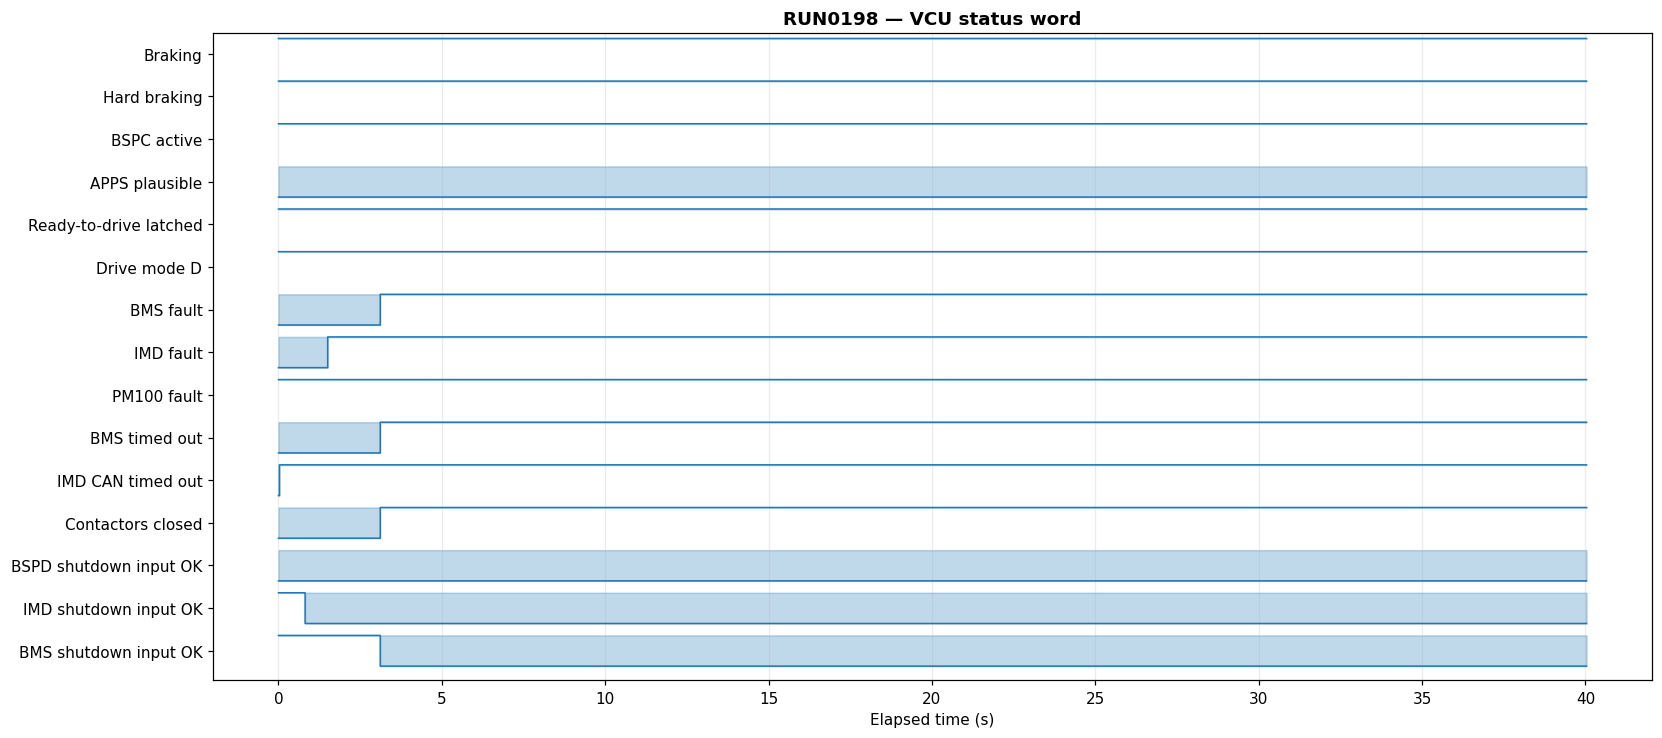

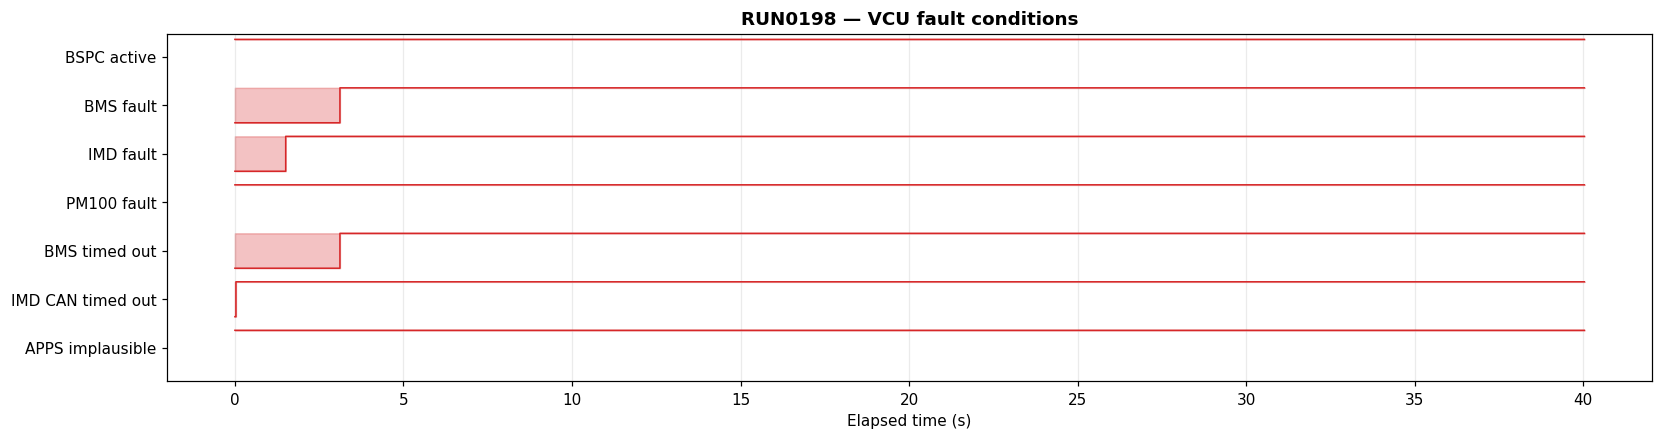

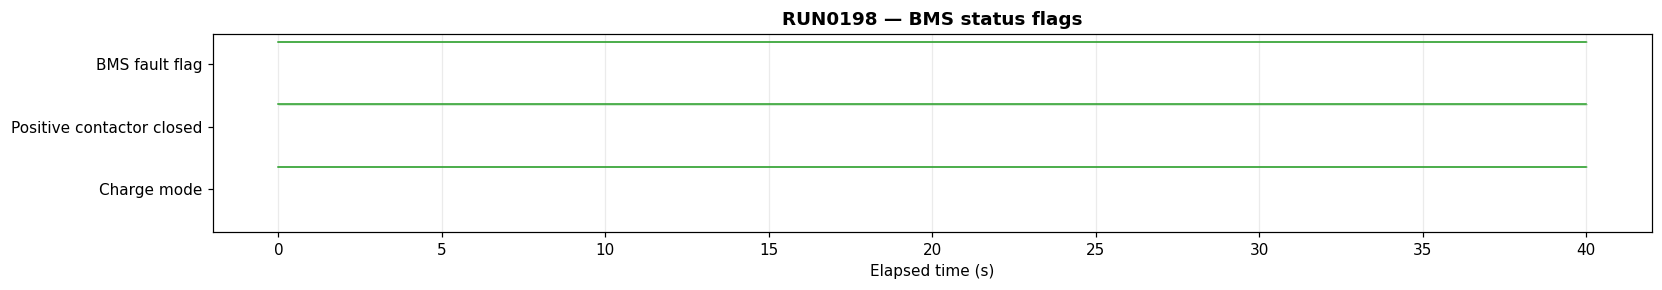

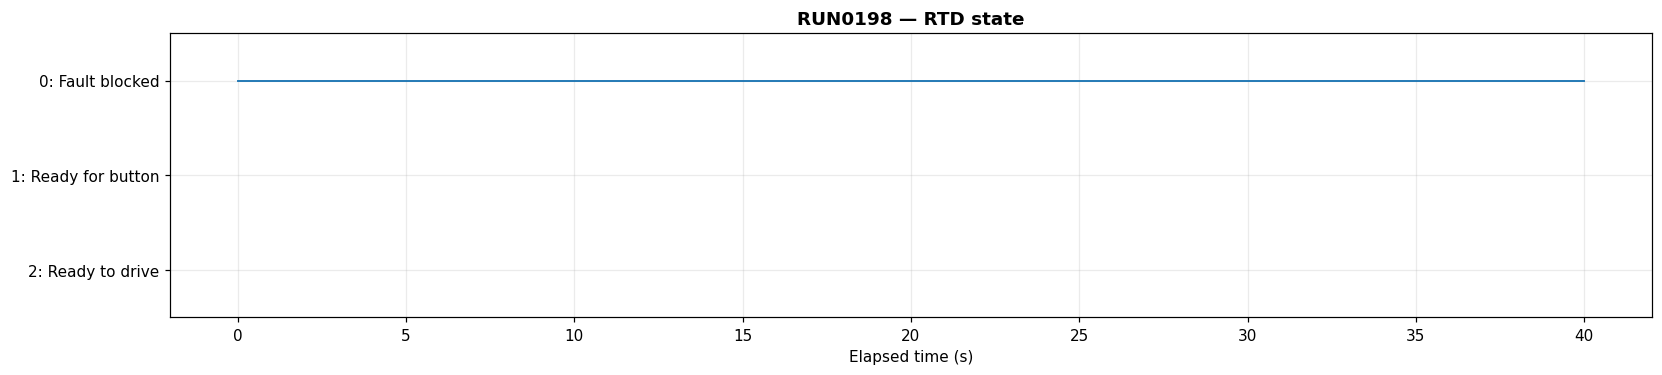

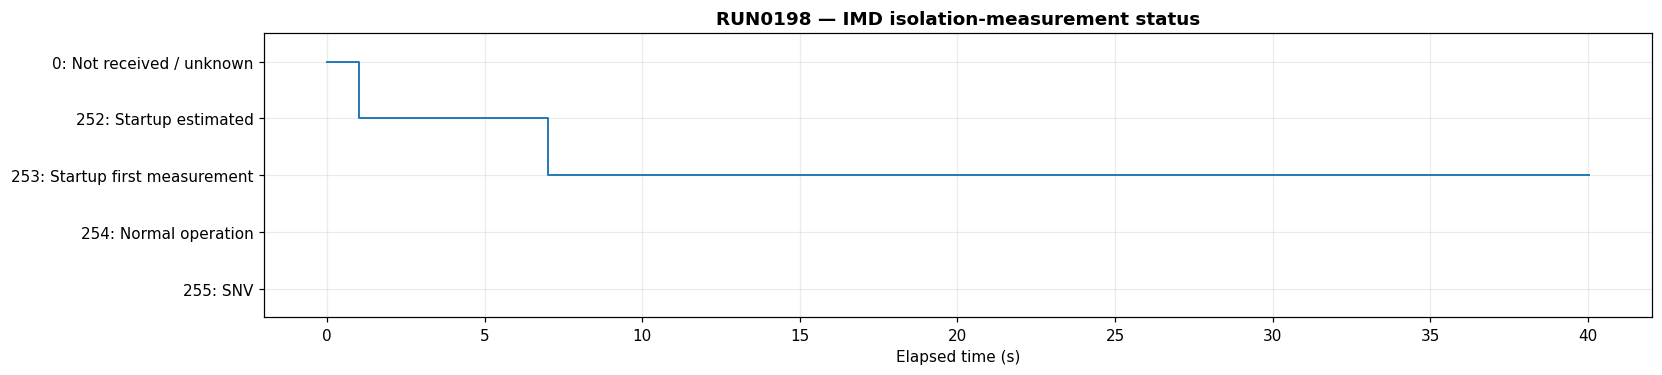

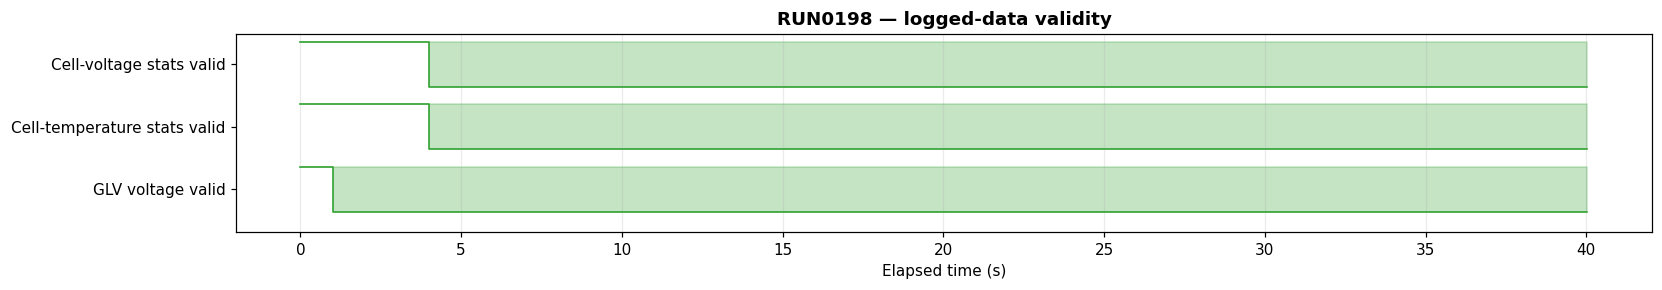

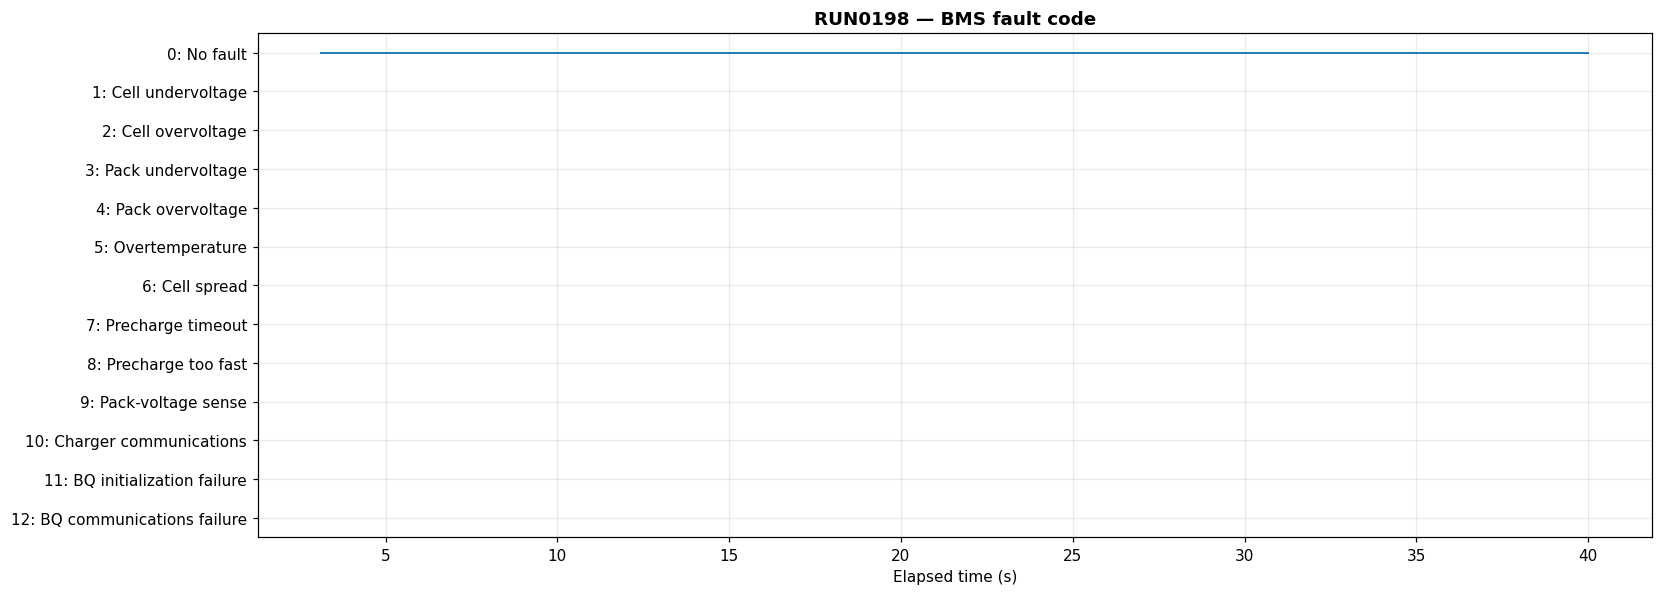

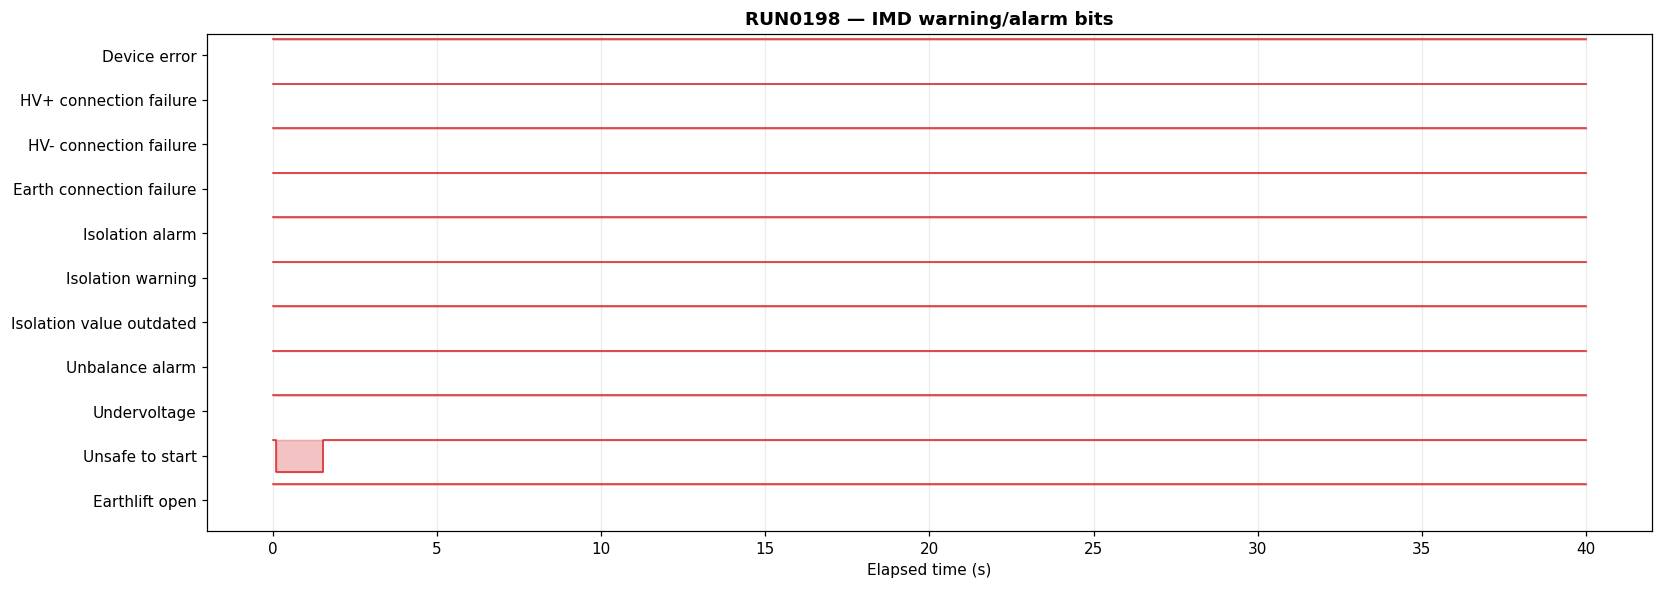

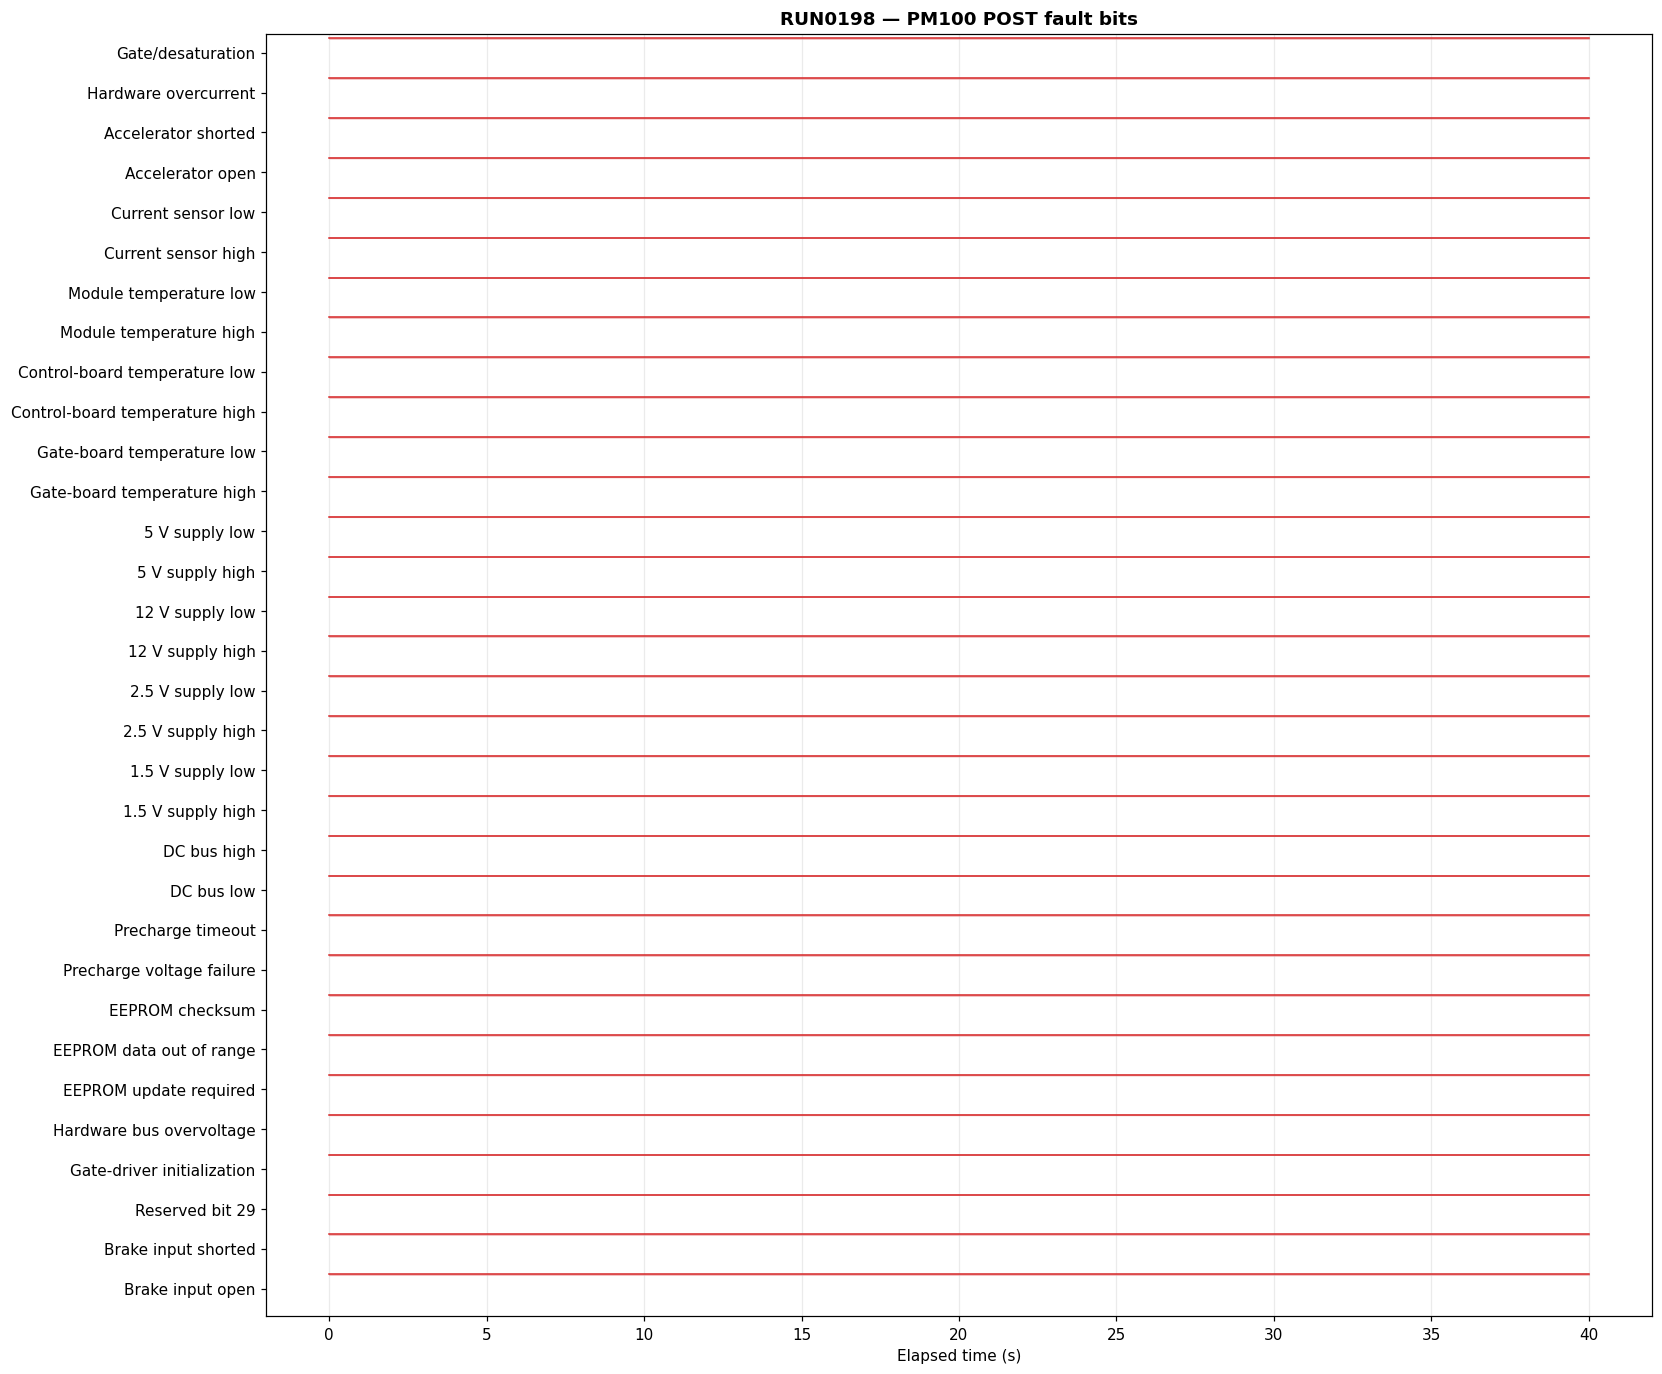

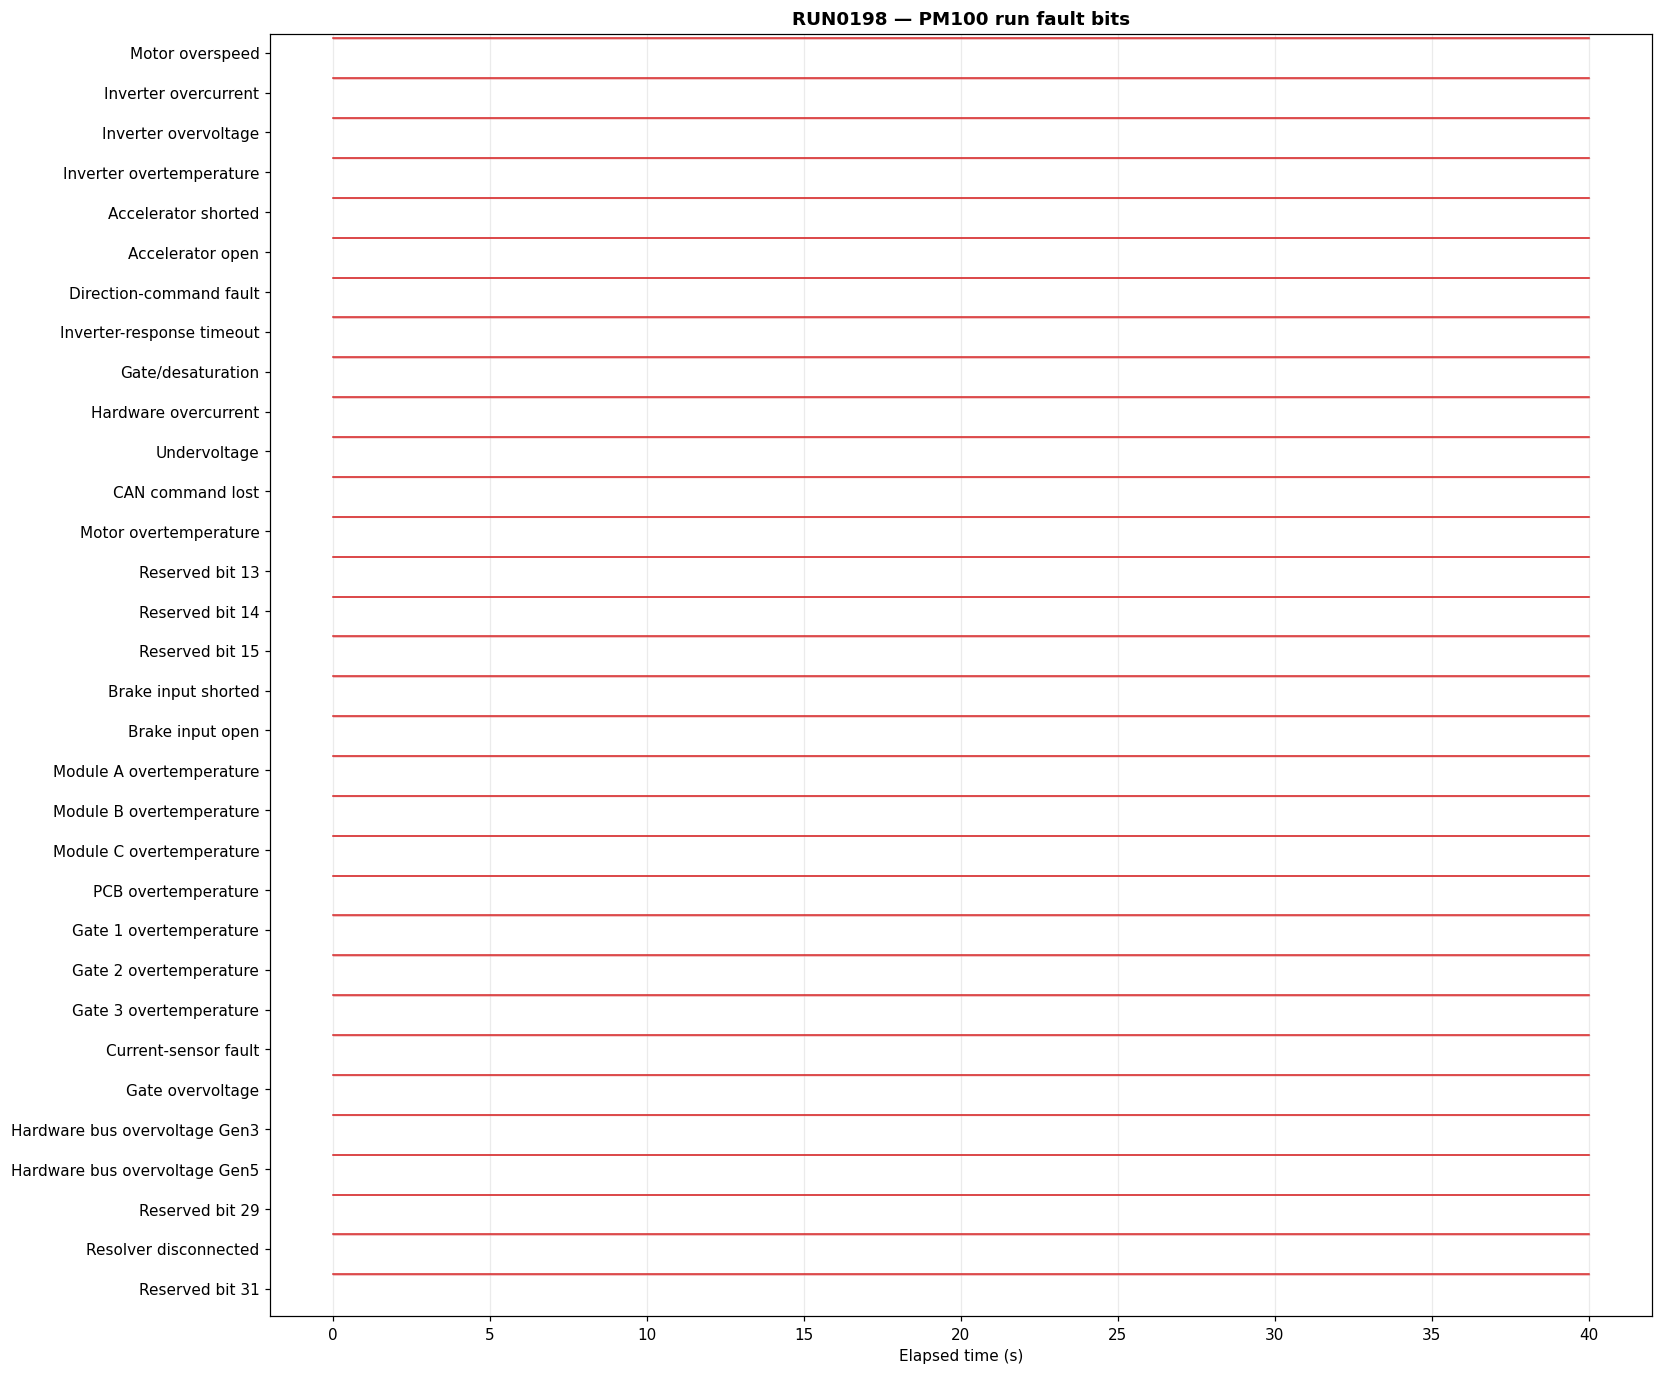

In [48]:
views = plot_all_status_faults(
    run,
    time_range_s=TIME_RANGE_S,
    show_clear_fault_bits=SHOW_CLEAR_FAULT_BITS,
    max_points=MAX_POINTS_PER_TRACE,
)

## Fault and warning intervals

The summary excludes normal status lanes and reports VCU fault conditions, nonzero BMS fault codes, IMD warnings/alarms, and PM100 POST/run faults. An interval ending at the log boundary may still have been active after logging stopped.

In [49]:
events = fault_event_table(run, views=views, time_range_s=TIME_RANGE_S)
summary = active_fault_summary(events)

if events.empty:
    print("No fault or warning intervals were active in the selected range.")
else:
    print("Active fault/warning summary")
    display(summary.round(3))
    print("Individual intervals")
    display(events.round(3))

Active fault/warning summary


,category,fault_or_status,episodes,first_start_s,last_end_s,total_duration_s
0,VCU fault conditions,BMS fault,1,0.0,3.115,3.115
1,VCU fault conditions,BMS timed out,1,0.0,3.115,3.115
2,VCU fault conditions,IMD CAN timed out,1,0.0,0.030,0.030
3,VCU fault conditions,IMD fault,1,0.0,1.506,1.506
4,IMD warnings and alarms,Unsafe to start,1,0.1,1.516,1.416


Individual intervals


,category,fault_or_status,episode,start_s,end_s,duration_s
0,VCU fault conditions,BMS fault,1,0.0,3.115,3.115
1,VCU fault conditions,BMS timed out,1,0.0,3.115,3.115
2,VCU fault conditions,IMD CAN timed out,1,0.0,0.030,0.030
3,VCU fault conditions,IMD fault,1,0.0,1.506,1.506
4,IMD warnings and alarms,Unsafe to start,1,0.1,1.516,1.416
